# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [3]:
#0
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VarNames = ["signal", "l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames = ["l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames = [name for name in VarNames[1:] if name not in RawNames]

files = ["SUSY-small.csv", "../Lab.7/SUSY-small.csv", "SUSY.csv", "../Lab.7/SUSY.csv"]
filename = ""
for path in files:
    if os.path.exists(path):
        filename = path
        break

if filename == "":
    raise FileNotFoundError("SUSY dataset not found. Put SUSY-small.csv from Lab 7 beside this notebook.")

df = pd.read_csv(filename, names=VarNames)
print("Dataset:", filename)
print("Rows:", len(df))
print("Signal:", int((df["signal"] == 1).sum()))
print("Background:", int((df["signal"] == 0).sum()))
display(df.head())

Dataset: ../Lab.7/SUSY-small.csv
Rows: 500000
Signal: 229245
Background: 270755


,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


In [4]:
filename="../Lab.7/SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [5]:
#1
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
#1
import scipy
from scipy.sparse import csr_matrix
import sklearn

print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Everything works!")

SciPy version: 1.15.3
Scikit-learn version: 1.7.2
Everything works!


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


In [ ]:
# In part a: Classification predicts categories (signal or background). Regression makes predictions of continuous variables.
# Grouping unlabeled observations into groups. The dimensionality reduction technique is used to reduce the number of features. 
# Model Selection: comparing models. The data is preprocessed.

# part b : The learning of weighted combinations of input features is done with part b: Linear classification methods.
# The inputs are used to estimate probabilities for the two classes in logistic regression.

# Part c: Linear Discriminant Analysis (LDA) finds a linear direction to separate the classes based on class means and common covariance matrix estimate.

### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

Training events: 400000
Testing events: 100000


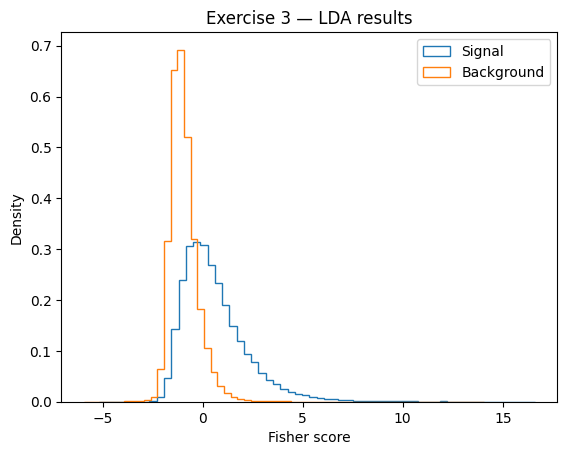

In [7]:
#3
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, auc

N_Train = int(len(df) * 0.8)
Train_Sample = df.iloc[:N_Train]
Test_Sample = df.iloc[N_Train:]

X_Train = Train_Sample[VarNames[1:]]
y_Train = Train_Sample["signal"]
X_Test = Test_Sample[VarNames[1:]]
y_Test = Test_Sample["signal"]

Fisher = LinearDiscriminantAnalysis()
Fisher.fit(X_Train, y_Train)

print("Training events:", len(Train_Sample))
print("Testing events:", len(Test_Sample))

scores = Fisher.decision_function(X_Test)
plt.hist(scores[y_Test == 1], bins=60, histtype="step", density=True, label="Signal")
plt.hist(scores[y_Test == 0], bins=60, histtype="step", density=True, label="Background")
plt.xlabel("Fisher score")
plt.ylabel("Density")
plt.title("Exercise 3 — LDA results")
plt.legend()
plt.show()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [12]:
N_Train = int(len(df) * 0.8)

Train_Sample = df.iloc[:N_Train]
Test_Sample = df.iloc[N_Train:]

X_Train = Train_Sample[VarNames[1:]]
y_Train = Train_Sample["signal"]

X_Test = Test_Sample[VarNames[1:]]
y_Test = Test_Sample["signal"]

Test_sig = Test_Sample[Test_Sample.signal == 1]
Test_bkg = Test_Sample[Test_Sample.signal == 0]

We can train the classifier as follows:

In [9]:
Fisher.fit(X_Train,y_Train)

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


We can plot the output, comparing signal and background:

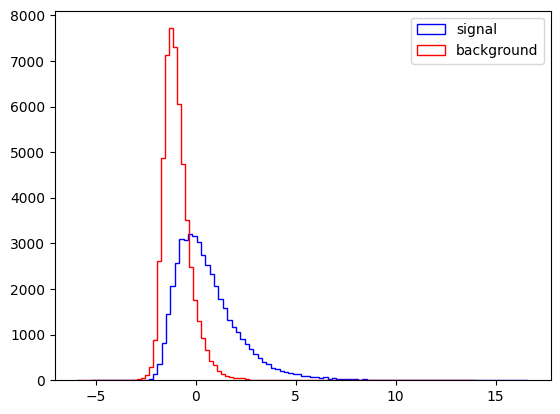

In [13]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

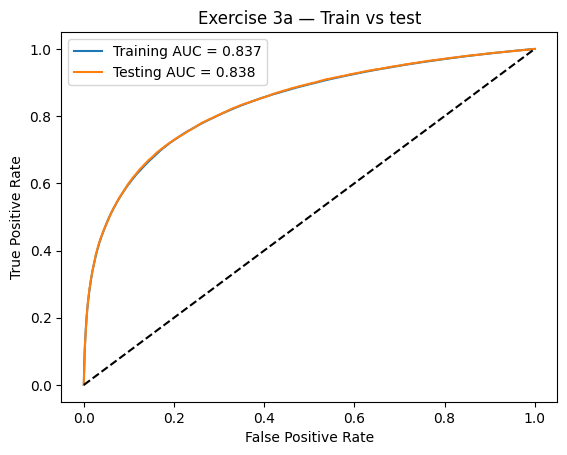

Training AUC: 0.8373
Testing AUC: 0.8383
A large training-versus-testing gap suggests overfitting. Compare the two numbers above.


In [14]:
#3a
train_scores = Fisher.decision_function(X_Train)
test_scores = Fisher.decision_function(X_Test)

fpr_train, tpr_train, _ = roc_curve(y_Train, train_scores)
fpr_test, tpr_test, _ = roc_curve(y_Test, test_scores)

plt.plot(fpr_train, tpr_train, label="Training AUC = " + str(round(auc(fpr_train, tpr_train), 3)))
plt.plot(fpr_test, tpr_test, label="Testing AUC = " + str(round(auc(fpr_test, tpr_test), 3)))
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 3a — Train vs test")
plt.legend()
plt.show()

print("Training AUC:", round(auc(fpr_train, tpr_train), 4))
print("Testing AUC:", round(auc(fpr_test, tpr_test), 4))
print("A large training-versus-testing gap suggests overfitting. Compare the two numbers above.")

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

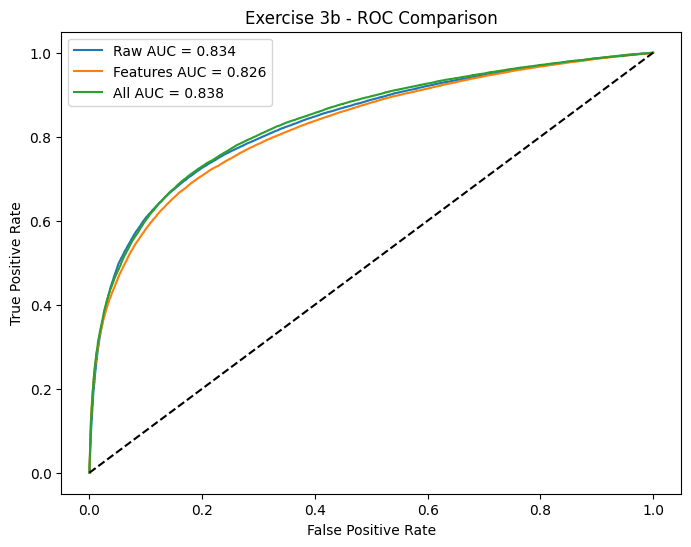

Raw AUC: 0.8344
Derived Features AUC: 0.8256
All Features AUC: 0.8384
Best separation: All 18 variables


In [15]:
#3b
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

raw_model = LinearDiscriminantAnalysis()
feature_model = LinearDiscriminantAnalysis()
all_model = LinearDiscriminantAnalysis()

raw_model.fit(Train_Sample[RawNames], y_Train)
feature_model.fit(Train_Sample[FeatureNames], y_Train)
all_model.fit(X_Train, y_Train)

raw_scores = raw_model.decision_function(Test_Sample[RawNames])
feature_scores = feature_model.decision_function(Test_Sample[FeatureNames])
all_scores = all_model.decision_function(X_Test)

fpr_raw, tpr_raw, _ = roc_curve(y_Test, raw_scores)
fpr_feature, tpr_feature, _ = roc_curve(y_Test, feature_scores)
fpr_all, tpr_all, _ = roc_curve(y_Test, all_scores)

auc_raw = auc(fpr_raw, tpr_raw)
auc_feature = auc(fpr_feature, tpr_feature)
auc_all = auc(fpr_all, tpr_all)

plt.figure(figsize=(8, 6))

plt.plot(fpr_raw, tpr_raw, label="Raw AUC = " + str(round(auc_raw, 3)))
plt.plot(fpr_feature, tpr_feature, label="Features AUC = " + str(round(auc_feature, 3)))
plt.plot(fpr_all, tpr_all, label="All AUC = " + str(round(auc_all, 3)))

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 3b - ROC Comparison")
plt.legend()
plt.show()

print("Raw AUC:", round(auc_raw, 4))
print("Derived Features AUC:", round(auc_feature, 4))
print("All Features AUC:", round(auc_all, 4))

results = [auc_raw, auc_feature, auc_all]
names = ["Raw quantities", "Derived features", "All 18 variables"]

best = results.index(max(results))

print("Best separation:", names[best])

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [16]:
#4a
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

models = [
    LogisticRegression(max_iter=1000),
    DecisionTreeClassifier(max_depth=5),
    GaussianNB()
]

names = ["Logistic Regression", "Decision Tree", "Naive Bayes"]

print("Selected classifiers:")
for name in names:
    print(name)

Selected classifiers:
Logistic Regression
Decision Tree
Naive Bayes


Logistic Regression Raw AUC: 0.8327
Logistic Regression Derived AUC: 0.8349
Logistic Regression All AUC: 0.8587


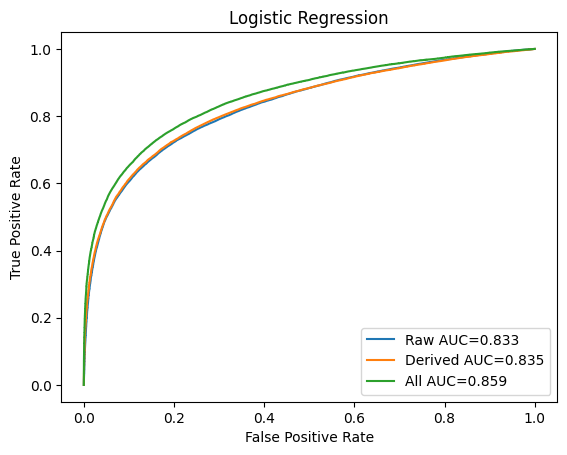

Decision Tree Raw AUC: 0.8378
Decision Tree Derived AUC: 0.8208
Decision Tree All AUC: 0.842


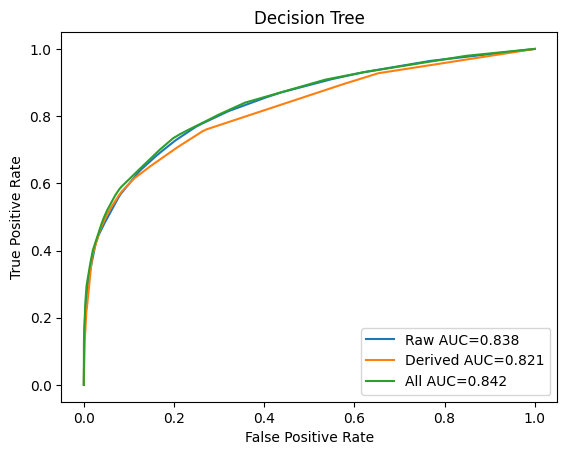

Naive Bayes Raw AUC: 0.8258
Naive Bayes Derived AUC: 0.787
Naive Bayes All AUC: 0.8122


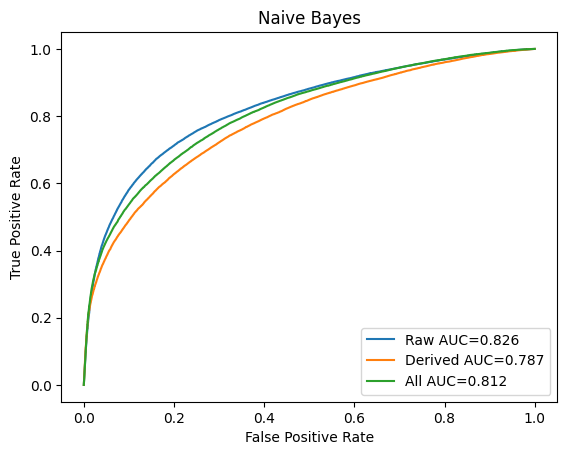

In [17]:
#4b
from sklearn.metrics import roc_curve, auc
from sklearn.base import clone

def compare_model(model, name):
    groups = [RawNames, FeatureNames, VarNames[1:]]
    labels = ["Raw", "Derived", "All"]

    for i in range(3):
        columns = groups[i]

        classifier = clone(model)
        classifier.fit(Train_Sample[columns], y_Train)

        scores = classifier.predict_proba(Test_Sample[columns])[:, 1]

        fpr, tpr, thresholds = roc_curve(y_Test, scores)
        area = auc(fpr, tpr)

        plt.plot(fpr, tpr, label=labels[i] + " AUC=" + str(round(area, 3)))

        print(name, labels[i], "AUC:", round(area, 4))

    plt.title(name)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()


for i in range(3):
    compare_model(models[i], names[i])

In [18]:
#4c
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.base import clone

groups = [RawNames, FeatureNames, VarNames[1:]]
group_names = ["Raw", "Derived", "All"]

best_auc = 0

for i in range(3):
    for j in range(3):
        model = clone(models[i])
        columns = groups[j]

        model.fit(Train_Sample[columns], y_Train)

        scores = model.predict_proba(Test_Sample[columns])[:, 1]

        fpr, tpr, thresholds = roc_curve(y_Test, scores)
        area = auc(fpr, tpr)

        if area > best_auc:
            best_auc = area
            best_model = model
            best_columns = columns
            best_name = names[i]
            best_group = group_names[j]

print("Best classifier:", best_name)
print("Best feature group:", best_group)
print("Best AUC:", round(best_auc, 4))

scores = best_model.predict_proba(Test_Sample[best_columns])[:, 1]

fpr, tpr, thresholds = roc_curve(y_Test, scores)

scenarios = [(10, 100), (100, 1000),
             (1000, 10000), (10000, 100000)]

for ns, nb in scenarios:
    best_significance = 0
    best_cut = 0

    for i in range(len(thresholds)):
        signal = ns * tpr[i]
        background = nb * fpr[i]

        if signal + background > 0:
            significance = signal / np.sqrt(signal + background)
        else:
            significance = 0

        if significance > best_significance:
            best_significance = significance
            best_cut = thresholds[i]

    print()
    print("Signal:", ns)
    print("Background:", nb)
    print("Best cutoff:", round(best_cut, 4))
    print("Maximum significance:", round(best_significance, 4))

Best classifier: Logistic Regression
Best feature group: All
Best AUC: 0.8587

Signal: 10
Background: 100
Best cutoff: 0.7933
Maximum significance: 1.7238

Signal: 100
Background: 1000
Best cutoff: 0.7933
Maximum significance: 5.451

Signal: 1000
Background: 10000
Best cutoff: 0.7933
Maximum significance: 17.2376

Signal: 10000
Background: 100000
Best cutoff: 0.7933
Maximum significance: 54.5101


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

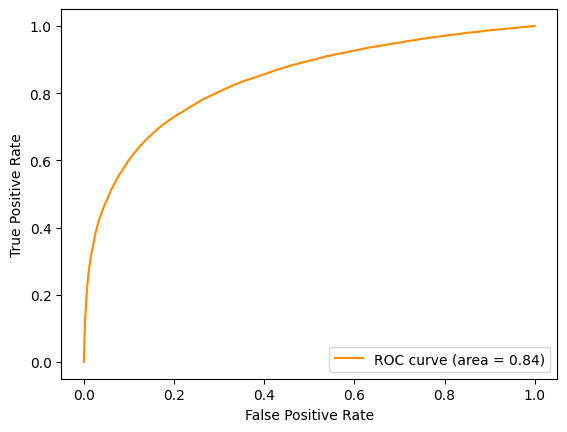

In [19]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [ ]:
# Precision: Signal events that are predicted, are signal.

# Recall (TPR): The proportion of the actual signal events that are correctly identified.

# FPR: False Positive Rate: Fraction of background events that are falsely called signal.

# Accuracy: Percentage of all events that are correctly identified.

# F1 Score: Score combining precision and recall.

# ROC Curve: A plot of TPR against FPR for various cut-off values.

# AUC: Area under the ROC Curve. The higher the AUC, the better the separation between the signal and background.

 Signal  Background    TPR    FPR    AUC  Precision  Recall     F1  Accuracy  Max Significance
     10         100 0.4559 0.0244 0.8587     0.6518  0.4559 0.5365    0.9284            1.7238
    100        1000 0.4559 0.0244 0.8587     0.6518  0.4559 0.5365    0.9284            5.4510
   1000       10000 0.4559 0.0244 0.8587     0.6518  0.4559 0.5365    0.9284           17.2376
  10000      100000 0.4559 0.0244 0.8587     0.6518  0.4559 0.5365    0.9284           54.5101


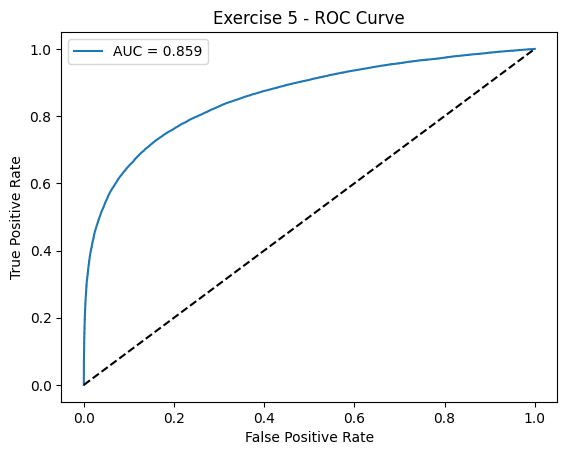

In [20]:
#5b
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score, accuracy_score

scores = best_model.predict_proba(Test_Sample[best_columns])[:, 1]

fpr, tpr, thresholds = roc_curve(y_Test, scores)
roc_auc = auc(fpr, tpr)

scenarios = [(10, 100), (100, 1000),
             (1000, 10000), (10000, 100000)]

results = []

for ns, nb in scenarios:

    best_significance = 0
    best_cut = 0

    for i in range(len(thresholds)):
        signal = ns * tpr[i]
        background = nb * fpr[i]

        if signal + background > 0:
            significance = signal / np.sqrt(signal + background)
        else:
            significance = 0

        if significance > best_significance:
            best_significance = significance
            best_cut = thresholds[i]

    predictions = (scores >= best_cut).astype(int)

    signal_count = sum(y_Test == 1)
    background_count = sum(y_Test == 0)

    weights = np.where(y_Test == 1,
                       ns / signal_count,
                       nb / background_count)

    precision = precision_score(y_Test, predictions,
                                sample_weight=weights,
                                zero_division=0)

    recall = recall_score(y_Test, predictions,
                          sample_weight=weights,
                          zero_division=0)

    f1 = f1_score(y_Test, predictions,
                  sample_weight=weights,
                  zero_division=0)

    accuracy = accuracy_score(y_Test, predictions,
                              sample_weight=weights)

    tp = recall
    fp = fpr[np.argmin(abs(thresholds - best_cut))]

    results.append([
        ns, nb, tp, fp, roc_auc,
        precision, recall, f1, accuracy,
        best_significance
    ])

columns = ["Signal", "Background", "TPR", "FPR",
           "AUC", "Precision", "Recall", "F1",
           "Accuracy", "Max Significance"]

table = pd.DataFrame(results, columns=columns)

print(table.round(4).to_string(index=False))

plt.plot(fpr, tpr, label="AUC = " + str(round(roc_auc, 3)))
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 5 - ROC Curve")
plt.legend()
plt.show()